# Recopilación de datos de NASA POWER

Este código accede a la API de NASA POWER para recopilar información de una coordenada.

## Librerías

Se usan las siguientes librerías:

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import requests

## Recopilación de datos:
Se recopilan datos de la API de NASA POWER:

In [ ]:
url_base = r"https://power.larc.nasa.gov/api/temporal/hourly/point?parameters=T2M&community=RE&longitude={longitude}&latitude={latitude}&start={inicio}&end={fin}&format=csv&header=false"

puntos=[]
for i in range(1,11):
    for j in range(1,11): puntos.append((i,j))
temperaturas = []

for (lat, long) in puntos:
    url = url_base.format(longitude=long, latitude=lat, inicio = 20041212, fin = 20041212)
    df = pd.read_csv(url)

    time_mapping = {"YEAR": "year", "MO": "month", "DY": "day", "HR": "hour"}
    df = df.rename(columns=time_mapping)
    df["time"] = pd.to_datetime(df[time_mapping.values()])
    df = df.drop(columns=time_mapping.values())
    df = df.set_index("time")

    temperaturas.append(np.average(df['T2M']))

[np.float64(26.17625), np.float64(26.341250000000002), np.float64(26.464583333333334), np.float64(26.584166666666665), np.float64(26.846666666666664), np.float64(27.349999999999998), np.float64(27.414583333333336), np.float64(27.007083333333338), np.float64(27.2), np.float64(24.82875), np.float64(26.287499999999998), np.float64(26.1675), np.float64(26.419166666666666), np.float64(26.68375), np.float64(26.823333333333334), np.float64(27.14083333333333), np.float64(27.243750000000002), np.float64(27.193749999999998), np.float64(27.1925), np.float64(24.8475), np.float64(26.78458333333333), np.float64(26.697916666666668), np.float64(26.732083333333335), np.float64(27.000833333333336), np.float64(27.120833333333337), np.float64(27.262083333333333), np.float64(27.287916666666664), np.float64(27.261666666666667), np.float64(26.655833333333334), np.float64(25.76), np.float64(27.402916666666666), np.float64(27.27916666666667), np.float64(27.346249999999998), np.float64(27.515416666666663), np.f

## Gráfico
Se genera usando matplotlib un diagrama de calor:

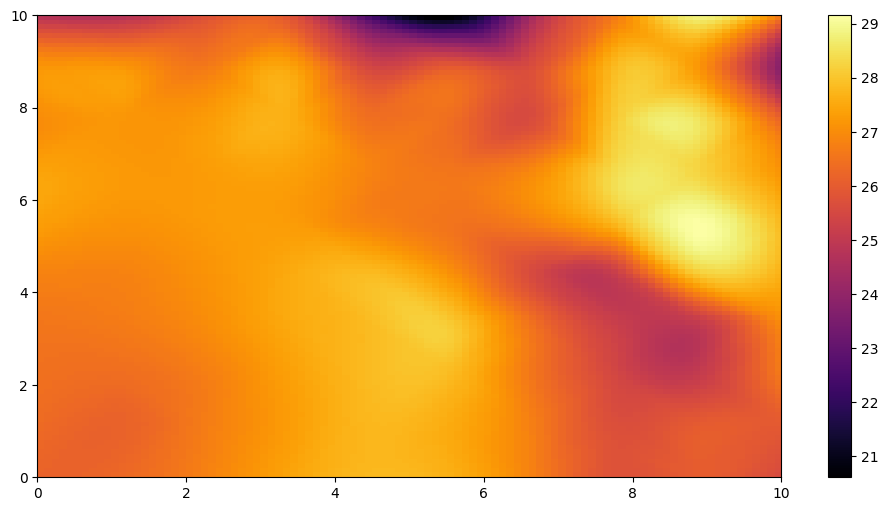

In [57]:
from scipy.interpolate import griddata

plt.rcParams['figure.figsize'] = [12,6]

N = 30j
extent = (np.min([i[0] for i in puntos]),np.max([i[0] for i in puntos]),np.min([i[1] for i in puntos]),np.max([i[1] for i in puntos]))  
xs,ys = np.mgrid[extent[0]:extent[1]:N, extent[2]:extent[3]:N]    

grid_x, grid_y = np.mgrid[1:10:100j, 1:10:100j]

grid_temp = griddata(([i[0] for i in puntos], [i[1] for i in puntos]), temperaturas, (grid_x, grid_y), method='cubic')

plt.imshow(grid_temp.T, extent=(0, 10, 0, 10), origin='lower', cmap='inferno', aspect='auto')
plt.colorbar()